In [ ]:
import pandas as pd

df = pd.read_parquet("../data/raw/prices.parquet")      #rows and colums
df.shape

(70897, 2)

In [ ]:
df.dtypes #Check if ts_utc is a date type and the price a number (float64)

ts_utc            datetime64[us, UTC]
price_euro_mwh                float64
dtype: object

In [9]:
df.head()

,ts_utc,price_euro_mwh
0,2018-09-30 22:00:00+00:00,59.53
1,2018-09-30 23:00:00+00:00,56.10
2,2018-10-01 00:00:00+00:00,51.41
3,2018-10-01 01:00:00+00:00,47.38
4,2018-10-01 02:00:00+00:00,47.59


In [8]:
df.tail()

,ts_utc,price_euro_mwh
70892,2026-11-01 18:00:00+00:00,NaN
70893,2026-11-01 19:00:00+00:00,NaN
70894,2026-11-01 20:00:00+00:00,NaN
70895,2026-11-01 21:00:00+00:00,NaN
70896,2026-11-01 22:00:00+00:00,NaN


In [4]:
df["price_euro_mwh"].describe()

count    70801.000000
mean        95.228740
std         90.535642
min       -500.000000
25%         39.070000
50%         77.020000
75%        119.290000
max        936.280000
Name: price_euro_mwh, dtype: float64

<Axes: title={'center': 'German day-ahead electricity price'}, xlabel='ts_utc'>

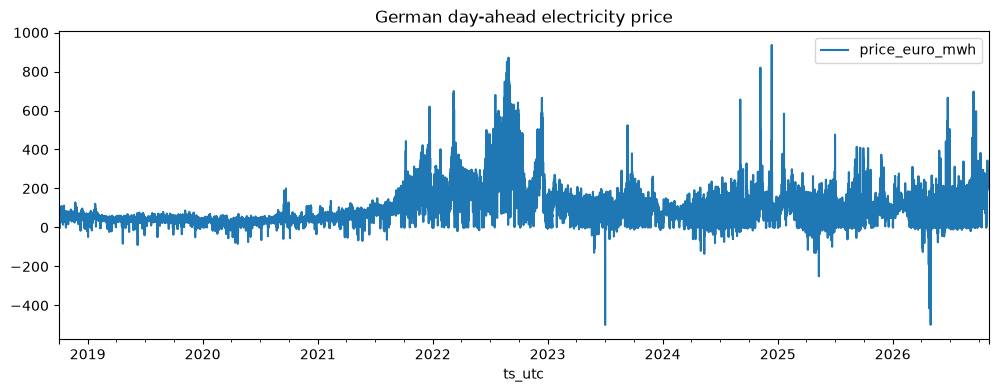

In [10]:
df.plot(x="ts_utc", y="price_euro_mwh", figsize=(12,4), title="German day-ahead electricity price")

In [11]:
print(df.loc[df["price_euro_mwh"].idxmax()])
print(df.loc[df["price_euro_mwh"].idxmin()])

ts_utc            2024-12-12 16:00:00+00:00
price_euro_mwh                       936.28
Name: 54354, dtype: object
ts_utc            2023-07-02 12:00:00+00:00
price_euro_mwh                       -500.0
Name: 41654, dtype: object


In [12]:
df[df["price_euro_mwh"] == -500]

,ts_utc,price_euro_mwh
41654,2023-07-02 12:00:00+00:00,-500.0


In [13]:
df.nsmallest(5, "price_euro_mwh")

,ts_utc,price_euro_mwh
41654,2023-07-02 12:00:00+00:00,-500.00
66469,2026-05-01 11:00:00+00:00,-499.00
66470,2026-05-01 12:00:00+00:00,-474.97
66349,2026-04-26 11:00:00+00:00,-413.77
66350,2026-04-26 12:00:00+00:00,-413.25


## First look: notes

- Data: hourly German day-ahead prices from Oct 2018 to today, about 70,900 hours.

- Highest price: 936.28 €/MWh on 2024-12-12 16:00(UTC) and 17:00(German Time) probably a cold winter evening 

- Lowest price: -500 €/MWh on 2023-07-02 12:00 UTC (14:00 German time, a sunny
  Sunday) and the second lowest happened recently in 2026-05-01 which was -499.00 €/MWh which came close (a public holiday)

- Prices were calm in 2019–2020 and exploded during the 2022 energy crisis.

- cannot see a repeating pattern because eight years of hours is squashed, maybe we zoom it in one particular week and check

- Negative prices seem to happen more often from 2023 on → check next session.

- Missing values are only the next 4 days(Future) Today is 28-10-2026 (prices not published yet).